In [1]:
# Run only if needed:
# %pip install numpy pandas scipy matplotlib

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy.linalg import solve

np.random.seed(42)
print('Libraries imported successfully')

Libraries imported successfully


In [2]:
DATA_PATH = 'property_transactions.csv'

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
else:
    # Fallback sample data if the CSV is not in the same folder as the notebook.
    rng = np.random.default_rng(42)
    n = 120
    latitude = rng.uniform(12.85, 13.15, n)
    longitude = rng.uniform(80.05, 80.35, n)
    dates = pd.to_datetime(rng.choice(pd.date_range('2025-01-01', periods=365, freq='D'), n))
    spatial = (65*np.exp(-(((latitude-13.05)/0.07)**2 + ((longitude-80.25)/0.08)**2)) +
               40*np.exp(-(((latitude-12.92)/0.05)**2 + ((longitude-80.12)/0.06)**2)))
    demand_score = np.maximum(3, 20 + spatial + 8*np.sin(2*np.pi*pd.DatetimeIndex(dates).month/12) + rng.normal(0, 5, n))
    df = pd.DataFrame({
        'transaction_id': [f'TXN{i:04d}' for i in range(1, n+1)],
        'transaction_date': pd.DatetimeIndex(dates).strftime('%Y-%m-%d'),
        'latitude': latitude, 'longitude': longitude,
        'property_price_inr': np.maximum(1500000, 3500000 + spatial*60000 + rng.normal(0, 400000, n)).round().astype(int),
        'demand_score': demand_score.round(2)
    })

df.head()

,transaction_id,transaction_date,latitude,longitude,property_price_inr,demand_score
0,TXN0001,2025-04-16,13.082187,80.225229,5570958,73.27
1,TXN0002,2025-10-30,12.981664,80.244954,4486016,37.63
2,TXN0003,2025-04-02,13.107579,80.075333,2923991,25.95
3,TXN0004,2025-10-18,13.059210,80.174742,4149027,40.21
4,TXN0005,2025-06-18,12.878253,80.062484,3705582,35.31


In [3]:
print('Rows and columns:', df.shape)
print('\nMissing values:\n', df.isna().sum())
df.describe(include='all')

Rows and columns: (120, 6)

Missing values:
 transaction_id        0
transaction_date      0
latitude              0
longitude             0
property_price_inr    0
demand_score          0
dtype: int64


,transaction_id,transaction_date,latitude,longitude,property_price_inr,demand_score
count,120,120,120.000000,120.000000,1.200000e+02,120.000000
unique,120,105,NaN,NaN,NaN,NaN
top,TXN0001,2025-12-04,NaN,NaN,NaN,NaN
freq,1,3,NaN,NaN,NaN,NaN
mean,NaN,NaN,12.999614,80.196236,4.480844e+06,37.140500
std,NaN,NaN,0.082123,0.090339,9.857096e+05,17.214892
min,NaN,NaN,12.852209,80.054181,2.684203e+06,9.300000
25%,NaN,NaN,12.931195,80.109682,3.771846e+06,24.697500
50%,NaN,NaN,12.991098,80.197705,4.225640e+06,33.270000
75%,NaN,NaN,13.068388,80.276085,5.030934e+06,46.707500


In [4]:
required = {'transaction_date', 'latitude', 'longitude', 'demand_score'}
missing = required - set(df.columns)
if missing:
    raise ValueError(f'Missing required columns: {sorted(missing)}')

df['transaction_date'] = pd.to_datetime(df['transaction_date'], errors='coerce')
for col in ['latitude', 'longitude', 'demand_score']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=['transaction_date', 'latitude', 'longitude', 'demand_score'])
df = df[df['latitude'].between(-90, 90) & df['longitude'].between(-180, 180)].copy()
df['month'] = df['transaction_date'].dt.to_period('M').astype(str)
selected_month = sorted(df['month'].unique())[-1]
period = df[df['month'] == selected_month].copy()
if len(period) < 3:
    period = df.copy()
    selected_month = 'all periods (fallback)'
print('Selected period:', selected_month)
print('Valid records:', len(period))
period.head()

Selected period: 2025-12
Valid records: 13


,transaction_id,transaction_date,latitude,longitude,property_price_inr,demand_score,month
10,TXN0011,2025-12-07,12.961239,80.101178,4598507,29.99,2025-12
18,TXN0019,2025-12-05,13.098289,80.284821,5826421,51.74,2025-12
22,TXN0023,2025-12-18,13.141209,80.331348,3337688,30.12,2025-12
30,TXN0031,2025-12-30,13.073429,80.297888,5674976,65.56,2025-12
34,TXN0035,2025-12-17,12.990867,80.082573,3886869,29.89,2025-12


Unique spatial locations: 13


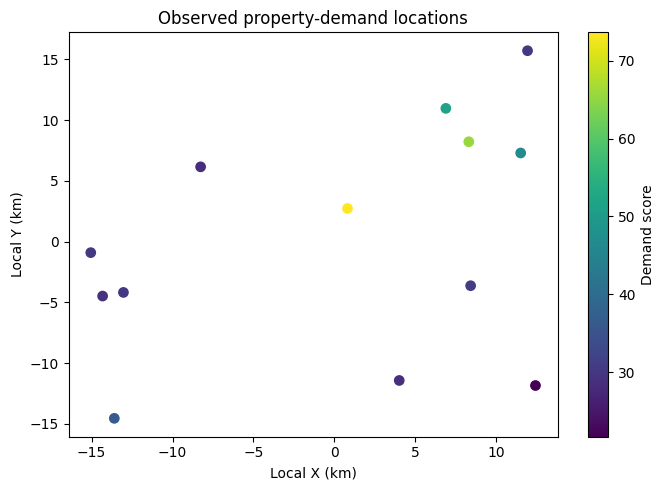

In [5]:
lat0 = float(period['latitude'].mean())
lon0 = float(period['longitude'].mean())
x = (period['longitude'].to_numpy() - lon0) * 111.32 * np.cos(np.deg2rad(lat0))
y = (period['latitude'].to_numpy() - lat0) * 110.57
coords = pd.DataFrame({'x': x, 'y': y, 'demand': period['demand_score'].to_numpy()})
coords = coords.groupby(['x', 'y'], as_index=False)['demand'].mean()
xy = coords[['x', 'y']].to_numpy(dtype=float)
values = coords['demand'].to_numpy(dtype=float)
if len(values) < 3:
    raise ValueError('Need at least 3 unique locations for Ordinary Kriging.')
print('Unique spatial locations:', len(values))
plt.figure(figsize=(7, 5))
plt.scatter(xy[:, 0], xy[:, 1], c=values, s=45)
plt.xlabel('Local X (km)'); plt.ylabel('Local Y (km)')
plt.title('Observed property-demand locations')
plt.colorbar(label='Demand score'); plt.tight_layout(); plt.show()

Nugget=23.533, partial sill=352.990, range=17.260 km


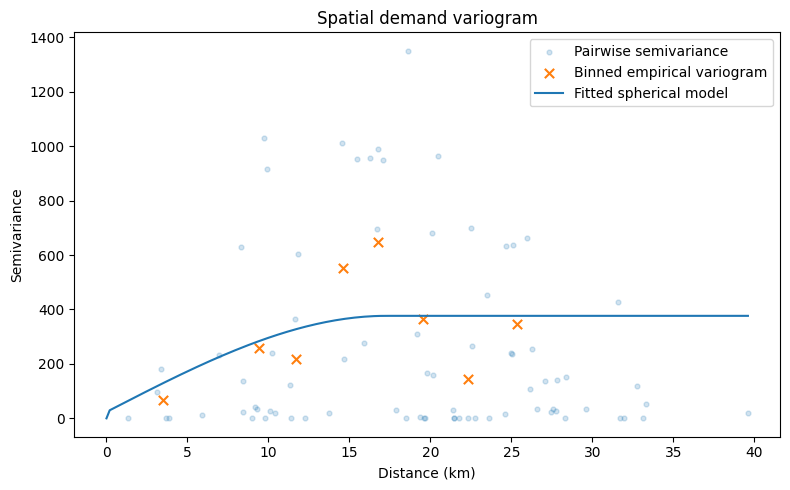

In [6]:
def spherical_variogram(h, nugget, sill, range_):
    h = np.asarray(h, dtype=float)
    hr = h / max(float(range_), 1e-12)
    structure = np.where(hr < 1, sill * (1.5*hr - 0.5*hr**3), sill)
    return np.where(h == 0, 0.0, nugget + structure)

d_train = cdist(xy, xy)
ii, jj = np.triu_indices(len(values), k=1)
distances = d_train[ii, jj]
pair_gamma = 0.5 * (values[ii] - values[jj])**2
positive = distances > 0
distances, pair_gamma = distances[positive], pair_gamma[positive]
maxd = np.quantile(distances, 0.8)
edges = np.linspace(0, maxd, 11)
lag_h, lag_gamma = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    mask = (distances >= lo) & (distances < hi)
    if mask.sum() >= 4:
        lag_h.append(float(distances[mask].mean()))
        lag_gamma.append(float(pair_gamma[mask].mean()))
lag_h, lag_gamma = np.array(lag_h), np.array(lag_gamma)

variance = max(float(np.var(values)), 1.0)
best = None
for nugget_try in np.linspace(0, 0.25*variance, 6):
    for sill_try in np.linspace(0.5*variance, 1.5*variance, 9):
        for range_try in np.linspace(max(lag_h.min(), 1e-4), maxd, 16):
            fitted = spherical_variogram(lag_h, nugget_try, sill_try, range_try)
            loss = np.mean((lag_gamma - fitted)**2)
            if best is None or loss < best[0]:
                best = (loss, nugget_try, sill_try, range_try)
_, nugget, sill, range_ = best
print(f'Nugget={nugget:.3f}, partial sill={sill:.3f}, range={range_:.3f} km')

plt.figure(figsize=(8, 5))
plt.scatter(distances, pair_gamma, alpha=0.2, s=12, label='Pairwise semivariance')
plt.scatter(lag_h, lag_gamma, marker='x', s=45, label='Binned empirical variogram')
curve_x = np.linspace(0, distances.max(), 200)
plt.plot(curve_x, spherical_variogram(curve_x, nugget, sill, range_), label='Fitted spherical model')
plt.xlabel('Distance (km)'); plt.ylabel('Semivariance')
plt.title('Spatial demand variogram'); plt.legend(); plt.tight_layout(); plt.show()

In [7]:
def ordinary_kriging(train_xy, train_values, target_xy, nugget, sill, range_):
    n = len(train_values)
    gamma = spherical_variogram(cdist(train_xy, train_xy), nugget, sill, range_)
    system = np.zeros((n + 1, n + 1), dtype=float)
    system[:n, :n] = gamma
    system[:n, n] = 1.0
    system[n, :n] = 1.0
    target_gamma = spherical_variogram(cdist(train_xy, target_xy), nugget, sill, range_)
    rhs = np.vstack([target_gamma, np.ones((1, target_xy.shape[0]))])
    try:
        solution = solve(system, rhs, assume_a='sym')
    except Exception:
        solution = np.linalg.lstsq(system, rhs, rcond=None)[0]
    weights, lagrange = solution[:n, :], solution[n, :]
    prediction = train_values @ weights
    kriging_variance = np.maximum(np.sum(weights * target_gamma, axis=0) + lagrange, 0.0)
    return prediction, kriging_variance

grid_size = 100
gx = np.linspace(xy[:, 0].min(), xy[:, 0].max(), grid_size)
gy = np.linspace(xy[:, 1].min(), xy[:, 1].max(), grid_size)
XX, YY = np.meshgrid(gx, gy)
targets = np.column_stack([XX.ravel(), YY.ravel()])
pred, kriging_variance = ordinary_kriging(xy, values, targets, nugget, sill, range_)
ZZ = pred.reshape(XX.shape)
VV = kriging_variance.reshape(XX.shape)
print('Prediction grid:', ZZ.shape)
print('Predicted demand range:', round(float(pred.min()), 2), 'to', round(float(pred.max()), 2))
print('Mean Kriging variance:', round(float(kriging_variance.mean()), 3))

Prediction grid: (100, 100)
Predicted demand range: 22.31 to 70.93
Mean Kriging variance: 211.812


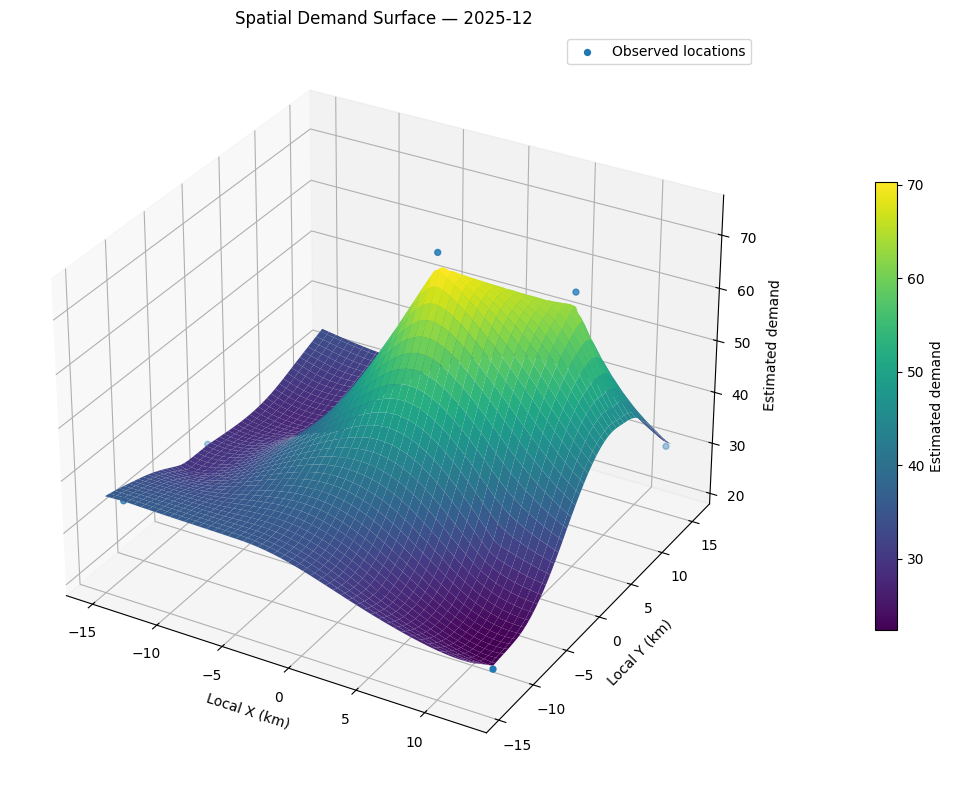

In [8]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
surface = ax.plot_surface(XX, YY, ZZ, cmap='viridis', linewidth=0, antialiased=True)
ax.scatter(xy[:, 0], xy[:, 1], values, s=18, label='Observed locations')
ax.set_title(f'Spatial Demand Surface — {selected_month}')
ax.set_xlabel('Local X (km)'); ax.set_ylabel('Local Y (km)'); ax.set_zlabel('Estimated demand')
fig.colorbar(surface, ax=ax, shrink=0.6, pad=0.1, label='Estimated demand')
ax.legend(); plt.tight_layout()
os.makedirs('outputs', exist_ok=True)
fig.savefig('outputs/demand_surface_3d.png', dpi=300, bbox_inches='tight')
plt.show()

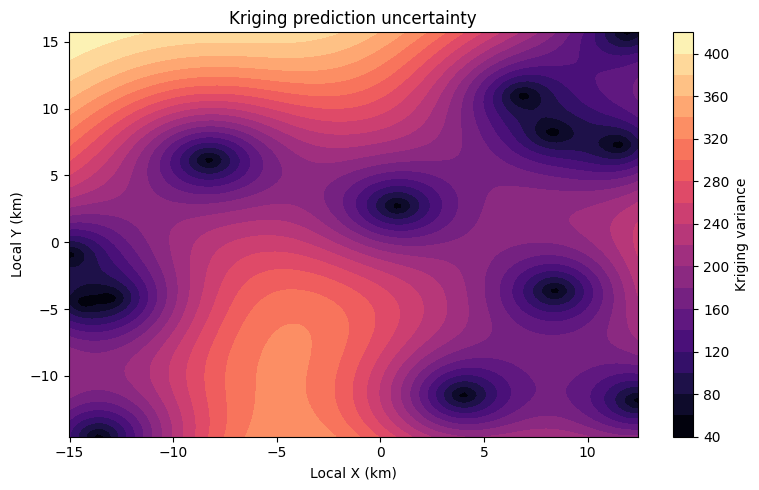

Saved outputs/demand_surface_3d.png, outputs/kriging_uncertainty.png, and outputs/predicted_demand_grid.csv


In [9]:
plt.figure(figsize=(8, 5))
plt.contourf(XX, YY, VV, levels=20, cmap='magma')
plt.colorbar(label='Kriging variance')
plt.xlabel('Local X (km)'); plt.ylabel('Local Y (km)')
plt.title('Kriging prediction uncertainty'); plt.tight_layout()
plt.savefig('outputs/kriging_uncertainty.png', dpi=300, bbox_inches='tight')
plt.show()

grid_output = pd.DataFrame({
    'x_km': targets[:, 0], 'y_km': targets[:, 1],
    'predicted_demand': pred, 'kriging_variance': kriging_variance
})
grid_output.to_csv('outputs/predicted_demand_grid.csv', index=False)
print('Saved outputs/demand_surface_3d.png, outputs/kriging_uncertainty.png, and outputs/predicted_demand_grid.csv')